Factor Models

# Setup

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Import the libraries used in this lecture: `pandas` as `pd`, `yfinance` as `yf`, `pandas_datareader` as `pdr`, `matplotlib.pyplot` as `plt`, `seaborn` as `sns`, and `statsmodels.api` as `sm`. Uncomment and run the following code.

In [ ]:
import pandas as pd
import yfinance as yf
import pandas_datareader as pdr # for FRED, Fama-French

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm # for OLS

# Factor Models

* Factor models are used in many financial applications, such as identifying the determinants of a security’s return as well as in cost of capital calculations, and performance evalution.
* Factors help explain the variation in a security’s return. 
* Here we will study two types of factor models
  - CAPM, a one-factor model
  - Fama-French 3-factor model

# CAPM

<mark>Q: What is the CAPM, and what does it say about a security's expected return?</mark>

* The formula for CAPM is:
$$E(r) = r_f + \beta \times E(r_M - r_f)$$
  - $r$ is the return on the stock
  - $r_f$ is the risk-free rate
  - $r_M$ is return on the market portfolio 
* To estimate the model using regression, we will add the residual term $\epsilon$ and intercept $\alpha$ and rearrange terms:

$$r - r_f = \alpha + \beta \times (r_{M} - r_f) + \epsilon$$


* So that we can regress stock EXCESS return $R \equiv r - r_f$ on market EXCESS return $R_M \equiv r_M -r_f$.

## Getting Data

* We will use IBM as example to apply CAPM. 
* The following code downloads the stock prices:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `stock_symbol` to `"IBM"` and `star_date` to `"2007-1-1"`, then download the data into `df` with `yf.download()` using `auto_adjust=True`, `multi_level_index=False` and `progress=False`. Uncomment and run the following code.

In [ ]:
stock_symbol = "IBM"
star_date = "2007-1-1"
df = yf.download(stock_symbol,
                  start=star_date,
                  auto_adjust=True,
                  multi_level_index=False,
                  progress=False)


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `df` with `.tail()`.

In [ ]:
df.tail()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the `"Close"` column of `df` into a variable called `close`, and display its first few rows with `.head()`.

In [ ]:
close = df['Close']
close.head()

## Monthly Return

* Next we calculate the *monthly* return on the stock

<mark>Q: How to calculate monthly returns from daily closing prices?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Downsample `close` to month-end frequency with `resample('ME').last()` and store it in `monthly_close`.

In [ ]:
monthly_close = close.resample('ME').last()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `monthly_close`.

In [ ]:
monthly_close.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the monthly return with `pct_change()`, store it in `r_monthly`, and display the first few rows.

In [ ]:
r_monthly = monthly_close.pct_change()
r_monthly.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Name the series by setting `r_monthly.name` to `'r_i'`, and display the first few rows.

In [ ]:
r_monthly.name = 'r_i'
r_monthly.head()

<mark>Q: How to make two monthly series that come from different sources line up on the same index?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Convert `r_monthly`'s `DatetimeIndex` to a monthly `PeriodIndex` with `.index.to_period('M')`, so it will line up with the Fama-French data later.

In [ ]:
r_monthly.index = r_monthly.index.to_period('M')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_monthly` again to confirm the new index.

In [ ]:
r_monthly.head()

## Make it a function

<mark>Q: How to turn the algorithm into a function?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Since the monthly return calculation will be repeatedly performed, let's collect the code and make it into a function. Uncomment and run the code below to have the function defined.

In [ ]:
def getMonthlyReturn(df, name):
    close = df["Close"]
    monthly_close = close.resample('ME').last()
    r_monthly = monthly_close.pct_change() * 100
    r_monthly.name = name
    r_monthly.index = r_monthly.index.to_period('M')
    r_monthly.dropna(inplace=True)

    return r_monthly

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Call `getMonthlyReturn()` on `df` with the name `"r_i"`, and store the result in `r_i`.

In [ ]:
r_i = getMonthlyReturn(df, 'r_i')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_i`.

In [ ]:
r_i.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_i` with the title `f"{stock_symbol} Monthly Return"`.

In [ ]:
r_i.plot(title=f'{stock_symbol} Monthly Return')

## Market Return

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Fetch the monthly Fama-French 3-factor dataset into `ff_dict_monthly`. Uncomment and run the following code, and inspect `ff_dict_monthly`.

In [ ]:
# Fetch the monthly Fama-French 3 Factors dataset
ff_dict_monthly = pdr.DataReader('F-F_Research_Data_Factors', 'famafrench', start="1900-01-01")

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ The monthly data is the DataFrame at index `[0]` of the dictionary — extract it into `ff_monthly`.

In [ ]:
ff_monthly = ff_dict_monthly[0]

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the first few rows of `ff_monthly`.

In [ ]:
ff_monthly.head()

<mark>Q: How to recover the total market return from the Fama-French factors?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the total market return `r_m` by adding the risk-free rate `'RF'` back to the market premium `'Mkt-RF'`.

In [ ]:
r_m = ff_monthly['Mkt-RF'] + ff_monthly['RF']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_m`.

In [ ]:
r_m.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_m` with the title `"S&P 500 Monthly Return"`.

In [ ]:
r_m.plot(title='S&P 500 Monthly Return')

## Risk-free Rate

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the risk-free rate column `'RF'` from `ff_monthly` into `r_f`.

In [ ]:
r_f = ff_monthly['RF']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_f`.

In [ ]:
r_f.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_f` with the title `"Risk-free Rate"`.

In [ ]:
r_f.plot(title='Risk-free Rate')

## Combining the rates

<mark>Q: How to combine several return series into a single DataFrame?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Combine `r_i`, `r_m` and `r_f` into one DataFrame called `returns` with `pd.concat(..., axis=1)`, and drop the rows with missing values using `.dropna()`.

In [ ]:
returns = pd.concat([r_i, r_m, r_f], axis=1).dropna()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `returns` with `.tail()`.

In [ ]:
returns.tail()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Rename the columns of `returns` to `["r_i", "r_m", "r_f"]`.

In [ ]:
returns.columns = ['r_i', 'r_m', 'r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `returns`.

In [ ]:
returns.plot()

## Calculate Excess Returns

<mark>Q: What is an excess return, and how to calculate it?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the excess return on the stock as `r_i` minus `r_f`, and store it in a new column `'R_i'`.

In [ ]:
returns['R_i'] = returns['r_i'] - returns['r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the excess return on the market as `r_m` minus `r_f`, and store it in a new column `'R_m'`.

In [ ]:
returns['R_m'] = returns['r_m'] - returns['r_f']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `returns`.

In [ ]:
returns.head()

## Scatter Plot: R_i vs. R_m

<mark>Q: How to visualize the relationship between a stock's excess return and the market's?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Make a scatter plot of `returns` with `'R_m'` on the x axis and `'R_i'` on the y axis, titled `'Excess Stock Return vs. Excess Market Return'`.

In [ ]:
returns.plot.scatter(x='R_m', y='R_i', title='Excess Stock Return vs. Excess Market Return')

## Estimate CAPM

<mark>Q: How to estimate the CAPM alpha and beta by regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set the dependent variable `y` to `returns['R_i']` and the independent variable `X` to `returns['R_m']`, add a constant to `X` with `sm.add_constant()` for the intercept, then create an OLS model and fit it into `capm_results`. Uncomment and run the following code.

In [ ]:
# Define the dependent variable (y) and independent variable (X)
y = returns['R_i']
X = returns['R_m']

# Add a constant to the independent variable for the intercept term (alpha)
X = sm.add_constant(X)

# Create and fit the OLS model
model = sm.OLS(y, X)
capm_results = model.fit()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Print the regression results with `capm_results.summary()`.

In [ ]:
capm_results.summary()

## Regression Line

<mark>Q: How to add the fitted regression line on top of a scatter plot?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Re-draw the scatter plot keeping its axes as `ax`, then add the fitted CAPM line in red using `capm_results.predict(sm.add_constant(returns['R_m']))`; set the title and axis labels, and turn on the grid and legend. Uncomment and run the following code.

In [ ]:
# Create the scatter plot using pandas plotting functionality and get the axes object
ax = returns.plot.scatter(x='R_m', y='R_i', figsize=(10, 6), label='Actual Returns')

# Plot the regression line on the same axes
# The independent variable X already includes the constant for prediction
ax.plot(returns['R_m'],
        capm_results.predict(sm.add_constant(returns['R_m'])),
        color='red', label='Fitted Line')

ax.set_title('Excess Stock Return vs. Excess Market Return with CAPM Fitted Line')
ax.set_xlabel('Excess Market Return (R_m)')
ax.set_ylabel('Excess Stock Return (R_i)')
ax.grid(True)
ax.legend()

## Intercept and Slope

* The regression model:

$$R_t = \alpha + \beta \times R_{M,t}  + \epsilon_t$$
(Recall $R_t$  and $R_{M,t}$ are excess returns, at time $t$)

* We can extract the intercept and slope estimate in the following way:

<mark>Q: How to extract the intercept and the slope from a fitted regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the intercept estimate from `capm_results.params['const']` into `alpha`, and display it.

In [ ]:
alpha = capm_results.params['const']
alpha

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Extract the slope estimate from `capm_results.params['R_m']` into `beta`, and display it.

In [ ]:
beta = capm_results.params['R_m']
beta

## Idiosyncratic Risk and Systematic Risk

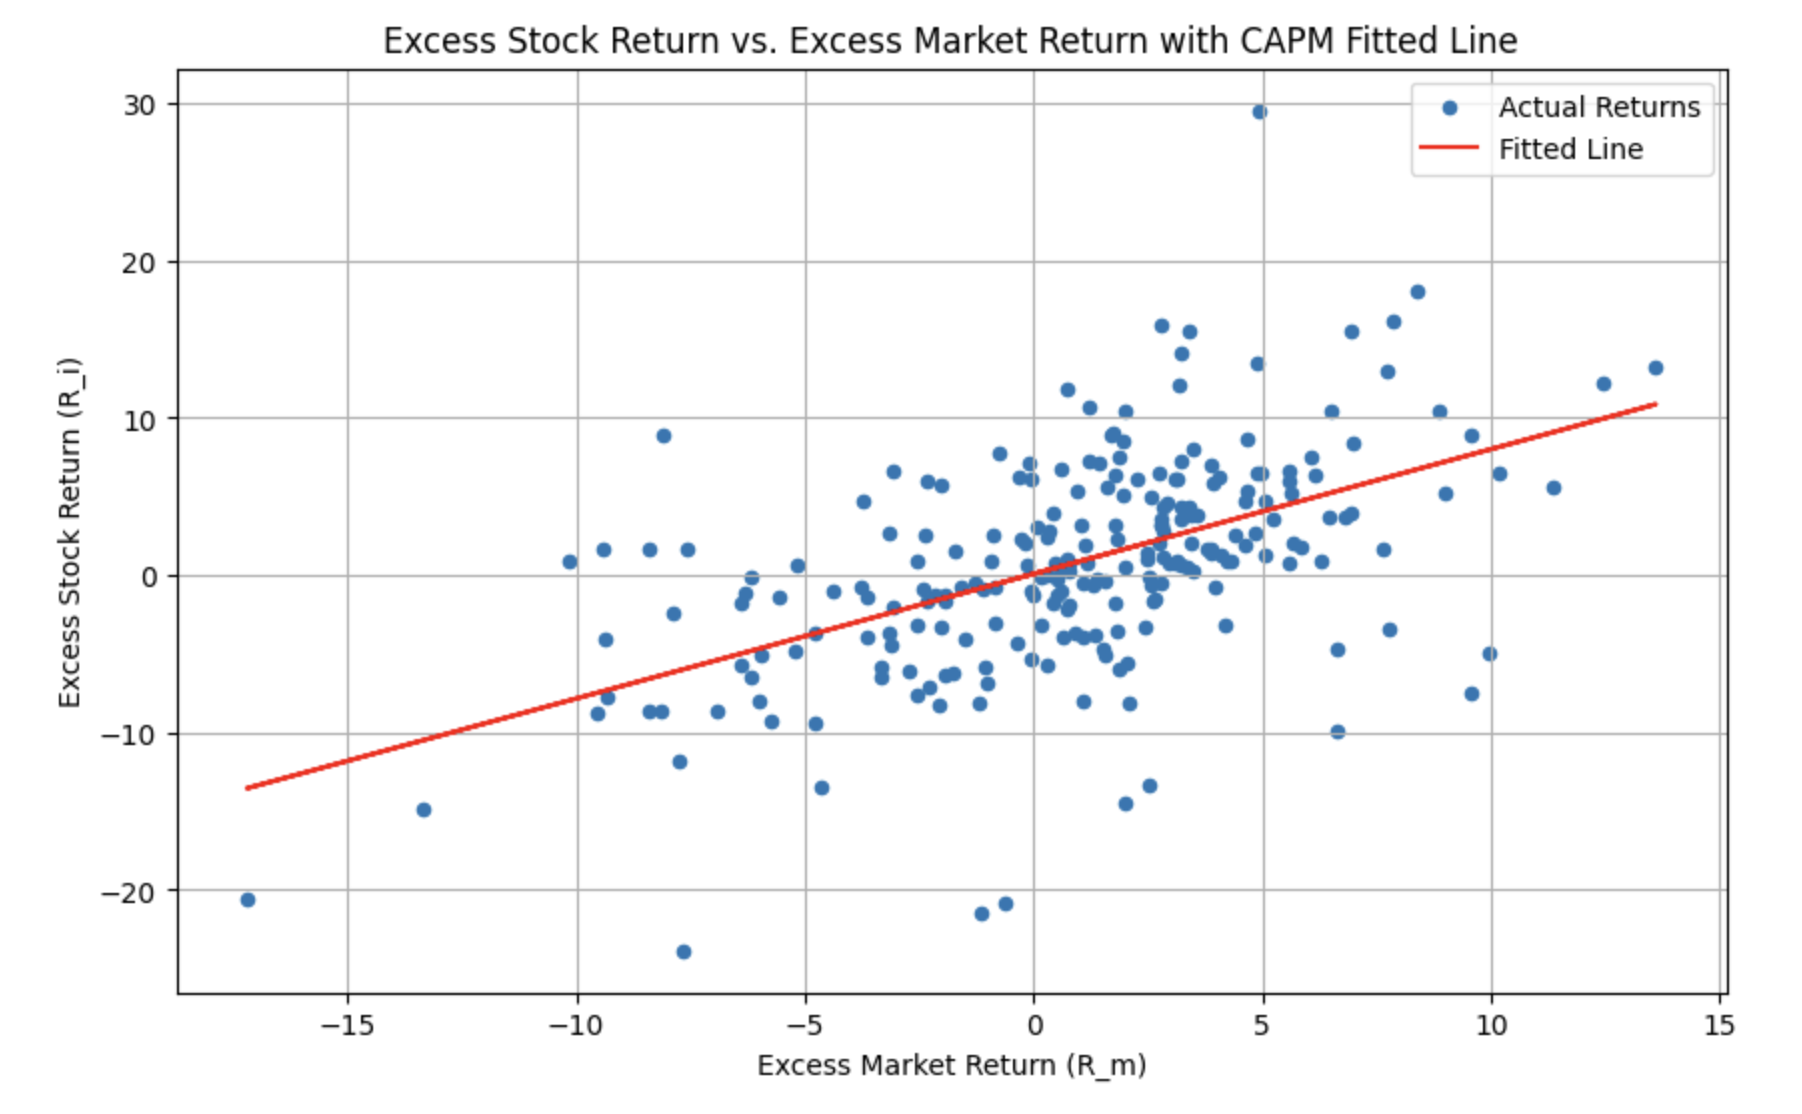

## Idiosyncratic Risk

<mark>Q: What is idiosyncratic risk, and how to measure it from the regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Get the regression residuals from `capm_results.resid` and store them in `CAPM_resid`.

In [ ]:
CAPM_resid = capm_results.resid

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `CAPM_resid` with the title `"Residuals"`.

In [ ]:
CAPM_resid.plot(title='Residuals')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the idiosyncratic risk as the variance of the residuals with `.var()`, store it in `idiosyncratic_risk`, and display it.

In [ ]:
idiosyncratic_risk = CAPM_resid.var()
idiosyncratic_risk

## Risk Decomposition

### Risk Decomposition: The Calculation

<mark>Q: How to decompose total risk into systematic risk and idiosyncratic risk?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the total risk as the variance of `returns['R_i']`, store it in `total_risk`, and display it.

In [ ]:
total_risk = returns['R_i'].var()
total_risk

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the systematic risk as `total_risk` minus `idiosyncratic_risk`, store it in `systematic_risk`, and display it.

In [ ]:
systematic_risk = total_risk - idiosyncratic_risk
systematic_risk

### Risk Decomposition: The Theory

* Again, from the regression model:

$$R_t = \alpha + \beta \times R_{M,t}  + \epsilon_t$$


* Taking variance of both sides:

$$\begin{aligned}
var(R_{t})	&= var(\alpha+\beta\times R_{M,t}+\epsilon_{t}) \\
	&= var(\beta\times R_{M,t}+\epsilon_{t}) \\
	&= var(\beta\times R_{M,t})+var(\epsilon_{t}) \\
	&= \beta^{2}\times var(R_{M,t})+var(\epsilon_{t})
 \end{aligned}$$



* Therefore systematic risk can also be calculated as $\beta^{2}\times var(R_{M,t})$

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the theory by computing `beta**2` times the variance of `returns['R_m']`, and compare it with the systematic risk you just calculated.

In [ ]:
print(beta**2 * returns['R_m'].var(), systematic_risk)

## Time-varying Beta

* Beta estimates depend on the time window chosen.
* Let's find out how the beta changes by rolling the window over time.

### Regression Function

* First we define a function that returns the regression beta (we will apply this function to a rolling window):

<mark>Q: How to estimate a beta that changes over time?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Define a function `get_beta(y_window)` that takes a rolling window of `R_i` values, picks the matching `R_m` values over the same dates, adds a constant, fits an OLS model, and returns the coefficient on `R_m`. Uncomment and run the following code.

In [ ]:
def get_beta(y_window):
    # y_window is the rolling window of R_i values
    idx = y_window.index                      # the dates in this window
    X = returns.loc[idx, 'R_m']               # matching R_m over the same dates
    X = sm.add_constant(X)
    model = sm.OLS(y_window, X)
    results = model.fit()
    return results.params['R_m']                  # 1 = coefficient for R_m column

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Test `get_beta()` on the whole sample and print its result next to `beta`, to check the two agree.

In [ ]:
print(get_beta(returns['R_i']), beta)

### Rolling Window Regression

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Apply `get_beta` to a rolling 60-month window of `returns['R_i']` with `.rolling(window=60).apply()`, and store the result in `rolling_betas`.

In [ ]:
rolling_betas = returns['R_i'].rolling(window=60).apply(get_beta)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `rolling_betas` with the title `"Time-Varying Beta, window size = 60 months"`.

In [ ]:
rolling_betas.plot(title='Time-Varying Beta, window size = 60 months')

# Size and Book-to-Market

## Portfolios Formed on Size and Book-to-Market

* Fama and French study portfolios formed based on firm size and book-to-market ratio. 
  - Sort all stocks according to size (market equity, ME) into 5 groups 
  - Within each size group, sort the stocks based on the ratio of book equity to market equity (BE/ME).
  - This generates an intersection of 25 portfolios.

### 25 Portfolios Formed on Size and Book-to-Market

* The returns on the 25 portfolios formed on size and book-to-market can be downloaded from Ken French's data library at http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Download the 25 portfolios formed on size and book-to-market into `ff25`. Uncomment and run the following code.

In [ ]:
# Fama-French 3 factors (monthly)
ff25 = pdr.DataReader("25_Portfolios_5x5", "famafrench",start="1900-1-1")

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Take table `[0]` from `ff25` into `size_BM_portfolios`, and display its first few rows.

In [ ]:
size_BM_portfolios = ff25[0]
size_BM_portfolios.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the average return of each column with `.mean()`, store it in `average_returns`, and display it.

In [ ]:
average_returns = size_BM_portfolios.mean()
average_returns

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Reshape `average_returns` into a 5x5 matrix with `.values.reshape(5, 5)`, and build a DataFrame `average_returns_mat` whose index is the size groups `['SMALL', 'ME2', 'ME3', 'ME4', 'BIG']` and whose columns are the book-to-market groups `['LoBM', 'BM2', 'BM3', 'BM4', 'HiBM']`. Uncomment and run the following code.

In [ ]:
# Reshape into a 5x5 Matrix
# The raw data is ordered: (Small-LoBM, Small-2... Small-Hi), then (ME2-LoBM...), etc.
# Reshaping creates a DataFrame where Index=Size, Columns=BM
matrix_data = average_returns.values.reshape(5, 5)

average_returns_mat = pd.DataFrame(
    matrix_data,
    index=['SMALL', 'ME2', 'ME3', 'ME4', 'BIG'],  # Size groups
    columns=['LoBM', 'BM2', 'BM3', 'BM4', 'HiBM'] # Book-to-Market groups. The sub-groups
)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display `average_returns_mat`.

In [ ]:
average_returns_mat

<mark>Q: How to show average returns across size and book-to-market groups in one picture?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Draw a heat map of `average_returns_mat` with `sns.heatmap()`. Uncomment and run the following code.

In [ ]:
sns.heatmap(average_returns_mat, annot=True, cmap='viridis', fmt=".2f", linewidths=.5)
plt.title('Average Monthly Returns by Size and Book-to-Market')
plt.xlabel('Book-to-Market')
plt.ylabel('Size')
plt.show()

## Empirical Difficulty of CAPM

* The popularity of the CAPM is due to its simplicity and it is grounded in finance theory. 
* However, the CAPM has not performed well in empirical testing. 
  - It cannot explain the difference in average return between small stocks and big stocks. 
  - It cannot explain the difference in average return between value stocks (stocks with high book-to-market ratio) and growth stocks (stocks with low book-to-market ratio). 
* This suggests other factors may need to be added to help explain the remaining variation in asset returns unexplained by the market. 
  - One such model that has gained popularity, especially in the academic community, is the Fama-French Three Factor (FF) Model.

# Fama-French Three-Factor Model

<mark>Q: What are the three factors in the Fama-French model?</mark>

* In the FF Model, we have

$$r-r_{f}=\beta\times\left(r_{M}-r_{f}\right)+h\times HML+s\times SMB$$

where
  - HML is the difference in the returns of portfolios with high B/M ratios and low B/M ratios
  - SMB is the difference in returns of portfolios of small company stocks and big company stocks.

## Factor Data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ We have already downloaded the Fama-French Research Data Factor from Ken French's data library at http://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html.

Check the first few rows of `ff_monthly`.

In [ ]:
ff_monthly.head()

## Mutual Fund

* Mutual funds are investments that pool your money together with other investors to purchase shares of a collection of stocks, bonds, or other securities, referred to as a portfolio, that might be difficult to recreate on your own. Mutual funds are typically overseen by a portfolio manager.

* As an example, we will study the performance of the fund called LSV Value Equity (LSVEX).

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `fund_symbol` to `"LSVEX"` and download its data into `fund_data` with `yf.download()` from `start="1900-01-01"`, using `auto_adjust=True`, `multi_level_index=False` and `progress=False`. Uncomment and run the following code:

In [ ]:
fund_symbol = "LSVEX"
fund_data = yf.download(fund_symbol,
                  start="1900-01-01",
                  auto_adjust=True,
                  multi_level_index=False,
                  progress=False)


$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `fund_data`.

In [ ]:
fund_data.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot the `"Close"` column of `fund_data` with the title `"LSVEX"`.

In [ ]:
fund_data['Close'].plot(title='LSVEX')

## Mutual fund returns

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Use `getMonthlyReturn()` to calculate the fund's monthly return, naming it `"r_p"`, and store it in `r_p`.

In [ ]:
r_p = getMonthlyReturn(fund_data, 'r_p')

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `r_p`.

In [ ]:
r_p.head()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Plot `r_p` with the title `"Monthly Return of LSVEX"`.

In [ ]:
r_p.plot(title='Monthly Return of LSVEX')

## Merging the data

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Concatenate `ff_monthly` and `r_p` along the columns with `pd.concat(..., axis=1)`, and store the result in `ff_returns`.

In [ ]:
ff_returns = pd.concat([ff_monthly, r_p], axis=1)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Check the last few rows of `ff_returns` with `.tail()`.

In [ ]:
ff_returns.tail()

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Drop the rows with missing values from `ff_returns` using `dropna(inplace=True)`.

In [ ]:
ff_returns.dropna(inplace=True)

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `ff_returns`.

In [ ]:
ff_returns.head()

## Excess Returns

Since we will run regression on excess returns (i.e. in excess of the risk-free rate), let’s calculate the excess returns on the mutual fund and save it as column `R_p`:

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Calculate the fund's excess return as `r_p` minus `RF`, and store it in a new column `"R_p"`.

In [ ]:
ff_returns['R_p'] = ff_returns['r_p'] - ff_returns['RF']

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Display the first few rows of `ff_returns`.

In [ ]:
ff_returns.head()

## Fama-French 3-Factor Model Regression

<mark>Q: How to estimate the Fama-French three-factor model by regression?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Set `y` to `ff_returns['R_p']` and `X` to the three factors `ff_returns[['Mkt-RF', 'SMB', 'HML']]`, add a constant, fit an OLS model into `FF_results`, and print its summary. Uncomment and run the following code.

In [ ]:
# Define the dependent variable (y)
y = ff_returns['R_p']

# Define the independent variables (X)
# Ensure column names match 'Mkt-RF' as it is in FF_factors
X = ff_returns[['Mkt-RF', 'SMB', 'HML']]

# Add a constant to the independent variable for the intercept term
X = sm.add_constant(X)

# Create and fit the OLS model
FF_model = sm.OLS(y, X)
FF_results = FF_model.fit()

# Display the regression results
print(FF_results.summary())

## Compared to CAPM

<mark>Q: How to tell whether the three-factor model explains the fund's returns better than the CAPM?</mark>

$\bbox[lightblue, 3pt]{\color{black}{\text{To do:}}}$ Run the same regression again with only `'Mkt-RF'` as the independent variable, fit it into `CAPM_results`, and print the summary so the two models can be compared. Uncomment and run the following code.

In [ ]:
# Define the dependent variable (y) for CAPM
y = ff_returns['R_p']

# Define the independent variable (X) for CAPM (only Mkt-RF)
X = ff_returns['Mkt-RF']

# Add a constant to the independent variable for the intercept term
X = sm.add_constant(X)

# Create and fit the OLS model for CAPM
CAPM_model = sm.OLS(y, X)
CAPM_results = CAPM_model.fit()

# Display the regression results
print(CAPM_results.summary())